# w2 · LSTM vs GRU for churn, manual segment (PyTorch)

Two recurrent models, an **LSTM** and a **GRU**, predict churn from the **90-day** tensors (14 channels) built in `w2_sequence_preprocessing.ipynb`.

The primary KPI is **log-loss**, because it measures the quality of the predicted probabilities. The evaluation is temporal:

| Part | Cohort | Use |
|---|---|---|
| `fit` | February | training |
| `stop` | February | validation and early stopping |
| `tune` | February | Optuna selection and threshold |
| `test` | March | final evaluation, once |
| `development` | All February | final refit |

Both models go through exactly the same pipeline: same split, same base seed, same Optuna budget (`N_TRIALS`), same search space and the same threshold rule. Only the recurrent cell changes. The notebook only orchestrates the pieces that live in `src/models/recurrent_models/` and `src/models/evaluation/`.

**Segment.** This run uses only the customers whose last transaction up to the cutoff is a payment without auto-renew (`SEGMENT = "manual"` in `src/models/constants.py`), the same population as the supervised models of `eda/16_supervised_manual_segment.ipynb`. They are read from `export-sequential-v6-manual/` (built by `w2_sequence_preprocessing.ipynb`, section 4.1): 111,751 February and 113,870 March customers, each selected at its own cutoff. The split and the scalers are computed on these customers only.

## 1. Configuration

The model settings, paths and Optuna budget live in `src/models/recurrent_models/config.py`. Here they are imported and displayed so it is explicit what the run uses.

- `N_TRIALS=10`: ten candidate configurations **per model**, the same budget as the trajectory models.
- `EPOCHS=40`: maximum epochs per trial.
- `PATIENCE=5`: early stopping when `stop` does not improve for five epochs.
- `BATCH_SIZE=512`: block/batch size.
- `layer_dim` is searched between 2 and 4; `hidden_dim` among 32, 64 and 128.
- `lr` and `weight_decay` are searched on a logarithmic scale.

Each model writes to its own folder, `artifacts/sherlock_w2_v6_manual/<model>/` (`optuna/`, `checkpoints/`, `evaluation/`). The side-by-side outputs go to `artifacts/sherlock_w2_v6_manual/comparison/`.

In [1]:
import torch; torch.cuda.is_available()

True

In [2]:
import os
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

warnings.filterwarnings("ignore")

# src.models reads the run selection once, at import time: a kernel that imported
# older code or another selection must be restarted.
import sys
_loaded = sys.modules.get("src.models.constants")
if _loaded is not None and (getattr(_loaded, "DATASET_VERSION", None) != 6
                            or _loaded.ALIGNMENT != os.environ.get("W2_ALIGNMENT", "calendar")):
    raise RuntimeError("This kernel holds an old src.models (or another run selection). "
                       "Restart the kernel and run the notebook from the top.")

from src.models.recurrent_models.config import (
    BATCH_SIZE,
    EPOCHS,
    EXPORT_DIR,
    FEATURE_DIR,
    HIDDEN_DIMS,
    INPUT_DIM,
    LAYER_DIM_RANGE,
    LR_RANGE,
    N_TRIALS,
    OUTPUT_DIM,
    PATIENCE,
    SEED,
    WEIGHT_DECAY_RANGE,
    model_dirs,
)
from src.models.recurrent_models.recurrent_classifier import GRUModel, LSTMModel
from src.models.recurrent_models.train import resolve_device
from src.models.evaluation.compare import COMPARISON_DIR

DEVICE = resolve_device()

# model_name -> model class. Every loop below iterates over this dict.
MODELS = {"lstm": LSTMModel, "gru": GRUModel}

settings = pd.DataFrame(
    [
        ("models", ", ".join(name.upper() for name in MODELS)),
        ("export_dir", str(EXPORT_DIR)),
        ("feature_dir", str(FEATURE_DIR)),
        ("comparison_dir", str(COMPARISON_DIR)),
        ("device", str(DEVICE)),
        ("seed", SEED),
        ("n_trials", N_TRIALS),
        ("epochs", EPOCHS),
        ("patience", PATIENCE),
        ("batch_size", BATCH_SIZE),
        ("input_dim", INPUT_DIM),
        ("output_dim", OUTPUT_DIM),
        ("hidden_dims", HIDDEN_DIMS),
        ("layer_dim_range", LAYER_DIM_RANGE),
        ("lr_range", LR_RANGE),
        ("weight_decay_range", WEIGHT_DECAY_RANGE),
    ],
    columns=["setting", "value"],
)
display(settings)

# Artifact folders per model.
pd.DataFrame({name.upper(): {k: str(v) for k, v in model_dirs(name).items()} for name in MODELS})

,setting,value
0,models,"LSTM, GRU"
1,export_dir,export-sequential-v6-manual
2,feature_dir,artifacts/sherlock_w2_v6_manual/feature_prepar...
3,comparison_dir,artifacts/sherlock_w2_v6_manual/comparison
4,device,cuda
5,seed,110
6,n_trials,10
7,epochs,40
8,patience,5
9,batch_size,512


,LSTM,GRU
artifacts,artifacts/sherlock_w2_v6_manual/lstm,artifacts/sherlock_w2_v6_manual/gru
optuna,artifacts/sherlock_w2_v6_manual/lstm/optuna,artifacts/sherlock_w2_v6_manual/gru/optuna
checkpoints,artifacts/sherlock_w2_v6_manual/lstm/checkpoints,artifacts/sherlock_w2_v6_manual/gru/checkpoints
evaluation,artifacts/sherlock_w2_v6_manual/lstm/evaluation,artifacts/sherlock_w2_v6_manual/gru/evaluation


## 2. Feature preparation

### 2.1 Data

`export-sequential-v6-manual` contains a `(users, 90, 14)` `float16` tensor, with days ordered from oldest to newest. The channels are:

- `0:8`: listening. Seven counters transformed with `log1p` plus the `active` flag.
- `8:11`: daily payment events (`tx_count`, `tx_paid_sum`, `tx_plan_days_sum`), zero on days without a payment.
- `11:14`: payment state carried forward (`tx_state_known`, `tx_days_since_last`, `tx_days_to_expire`).

The `is_churn` labels are aligned row by row with the tensor. Everything is computed from information available up to each cohort cutoff, so there is no temporal leakage.

The export is small (about 400 MB per cohort), so `load_prepared_data` loads it into RAM once and scales it once per phase (about 25 s each); every epoch then slices in-memory arrays. Exports above `W2_RAM_CACHE_GB` (default 8, e.g. the whole cohort) are read from the memory map block by block instead.

**Channels: 14.** The export holds exactly the channels the networks read: the 8 listening channels, 3 payment events and 3 payment states. The other six channels computed by the builder (cancel / auto-renew counters and flags, `tx_expiry_known`, `tx_state_ambiguous`) are almost constant in the manual segment and are not exported (`w2_sequence_preprocessing.ipynb`, section 7).

In [3]:
from src.models.feature_preparation.prepare import prepare

prepared = prepare()   # reads EXPORT_DIR, writes FEATURE_DIR (split + scalers of this run)

input: export-sequential-v6-manual | output: artifacts/sherlock_w2_v6_manual/feature_preparation | on_kaggle: False
dataset_version: 6 | cutoffs: {'train_feb': '2017-01-31', 'test': '2017-02-28'}
train_feb rows:   111,751 | label month: 2017-02 | churn rate: 0.3215
test      rows:   113,870 | label month: 2017-03 | churn rate: 0.4110
labelled cohorts: (225621, 4) | users in both months: 60478
stacked sequence view: (225621, 90, 14) float16
saved split_indices.npz and split_summary.csv | fit churn rate: 0.32151
part    cohort label_month  n_users  share_of_cohort  churn_rate  n_churn  n_stay
 fit train_feb     2017-02    83814         0.750007     0.32151    26947   56867
stop train_feb     2017-02    13969         0.125001     0.32150     4491    9478
tune train_feb     2017-02    13968         0.124992     0.32152     4491    9477
test      test     2017-03   113870         1.000000     0.41099    46800   67070
fitted phase 'fit': rows=83,814 | file=preprocessing/fit.json
fitted phase

In [4]:
from src.models.recurrent_models.data import load_prepared_data

data = load_prepared_data(feature_dir=FEATURE_DIR, export_dir=EXPORT_DIR)

print("tensor:", data.view.shape, data.view.dtype)
print("input_dim:", data.input_dim)
print("channels:", data.meta["sequences"]["lstm"]["channels"])
print("split sizes:", {part: len(rows) for part, rows in data.split.items()})
for part in ("fit", "stop", "tune", "test"):
    labels = data.labels(part)
    print(f"{part:4s} n={len(labels):>9,} | churn_rate={labels.mean():.4f}")

train_feb rows:   111,751 | label month: 2017-02 | churn rate: 0.3215
test      rows:   113,870 | label month: 2017-03 | churn rate: 0.4110
labelled cohorts: (225621, 4) | users in both months: 60478
sequence data: 225,621 rows | RAM cache on (needs 1.1 GB, limit 8 GB)
tensor: (225621, 90, 14) float16
input_dim: 14
channels: ['num_25', 'num_50', 'num_75', 'num_985', 'num_100', 'num_unq', 'total_secs', 'active', 'tx_count', 'tx_paid_sum', 'tx_plan_days_sum', 'tx_state_known', 'tx_days_since_last', 'tx_days_to_expire']
split sizes: {'fit': 83814, 'stop': 13969, 'tune': 13968, 'test': 113870, 'development': 111751}
fit  n=   83,814 | churn_rate=0.3215
stop n=   13,969 | churn_rate=0.3215
tune n=   13,968 | churn_rate=0.3215
test n=  113,870 | churn_rate=0.4110


### 2.2 Split

February is split once with a stable `msno` hash, stratified by label:

- `fit`: 75%.
- `stop`: 12.5%.
- `tune`: 12.5%.
- `test`: all of March, never used for any decision.
- `development`: all of February; used only for the final refit before predicting March.

This keeps the threshold honest: it is selected on `tune` and never re-searched on `test`.

In [5]:
split_table = pd.DataFrame(
    [
        {
            "part": part,
            "n_users": len(data.split[part]),
            "churn_rate": float(data.labels(part).mean()),
        }
        for part in ("fit", "stop", "tune", "test", "development")
    ]
)
split_table

,part,n_users,churn_rate
0,fit,83814,0.321510
1,stop,13969,0.321498
2,tune,13968,0.321521
3,test,113870,0.410995
4,development,111751,0.321509


### 2.3 Prepared dataset and batches

The existing `PreparedSequenceData` class encapsulates:

- the labels,
- the split indices,
- the tensor, held in RAM (raw once, scaled once per phase),
- the scalers fitted per phase.

Its `iter_batches` method returns batches of scaled rows as PyTorch tensors, sliced from the in-memory scaled tensor of the requested phase, so the scaler is applied once per phase instead of once per batch and epoch.

- `phase="fit"`: scaler fitted only on `fit`.
- `phase="development"`: scaler fitted on all of February.
- `drop_last=True`: avoids a final batch of size 1, which `BatchNorm1d` cannot normalise during training.

In [6]:
sample_rows = data.rows("fit")[:BATCH_SIZE]
xb, yb = next(
    iter(data.iter_batches(sample_rows, "fit", BATCH_SIZE, drop_last=True))
)
print("x:", xb.shape, xb.dtype)
print("y:", yb.shape, yb.dtype)
print("first user, channel 0, day 0:", float(xb[0, 0, 0]))

loaded raw tensor into RAM: (225621, 90, 14) float16 in 0.3s
scaled tensor for phase 'fit' cached in 5.6s
x: torch.Size([512, 90, 14]) torch.float32
y: torch.Size([512, 1]) torch.float32
first user, channel 0, day 0: 0.0


## 3. Model and training

### 3.1 Architecture: LSTM and GRU

The input is `(batch, 90, 14)`: the 14 channels of the export. Both networks stack between **2 and 4 recurrent layers** and share the same head; only the recurrent cell changes (`RecurrentClassifier` with `rnn_cls = nn.LSTM` or `nn.GRU`).

- **LSTM**: input, forget and output gates plus a cell state `c_t`. Four weight blocks per layer.
- **GRU**: update and reset gates, no separate cell state. Three weight blocks per layer, so about **25% fewer parameters** for the same `hidden_dim` and usually faster epochs.

In both cases the last hidden output `h_T` summarises the 90-day history. After `h_T`:

1. `BatchNorm1d(hidden_dim)` stabilises the hidden-state distribution.
2. `Linear(hidden_dim, 1)` produces a logit.
3. At prediction time, `Sigmoid` turns the logit into a churn probability.

`forward` returns only the logit, so both families expose the same interface. There is no dropout, as specified. Overfitting is controlled by `weight_decay`, BatchNorm and early stopping.

The loss is `BCEWithLogitsLoss`: the numerically stable version of binary cross-entropy that works directly with logits.

In [7]:
# Same configuration for both cells: same output shape, different parameter count.
for name, model_cls in MODELS.items():
    example = model_cls(
        input_dim=INPUT_DIM, hidden_dim=64, layer_dim=2, output_dim=OUTPUT_DIM
    ).to(DEVICE).eval()
    with torch.no_grad():
        logits = example(xb.to(DEVICE))
    n_params = sum(p.numel() for p in example.parameters())
    print(
        f"{name.upper():4s} | logits {tuple(logits.shape)} | parameters {n_params:,}"
        f" | example probabilities {torch.sigmoid(logits[:3]).cpu().numpy().ravel().round(3)}"
    )

LSTM | logits (512, 1) | parameters 53,953 | example probabilities [0.502 0.503 0.5  ]
GRU  | logits (512, 1) | parameters 40,513 | example probabilities [0.477 0.495 0.479]


### 3.2 Optimisation

- **AdamW** decouples weight decay from the adaptive step.
- `lr` and `weight_decay` are searched with Optuna.
- **Gradient clipping** at norm 1.0 for recurrent-network stability.
- **AMP** on GPU for speed.
- At most **40 epochs** per trial.
- **Early stopping** with `patience=5`: if `stop` does not improve, training stops and the best checkpoint is restored.
- No dropout.

### 3.3 Optuna

Optuna uses TPE and minimises `log_loss` on `tune`:

- trains on `fit`,
- validates on `stop`,
- evaluates on `tune`,
- restores the best `stop` state before computing the objective.

The search space is the same for both models:

- `layer_dim`: 2–4.
- `hidden_dim`: 32, 64, 128.
- `lr`: `1e-4` to `1e-2` on a logarithmic scale.
- `weight_decay`: `1e-6` to `1e-2` on a logarithmic scale.
- `batch_size`: fixed at 512.

Each study is written under `artifacts/sherlock_w2_v6_manual/<model>/optuna/`: the SQLite study, the trials CSV, the best-parameters JSON and the per-epoch history of the best trial.

In [8]:
from src.models.recurrent_models.tune import tune_model

best = {}
for name, model_cls in MODELS.items():
    print(f"\n===== {name.upper()} =====")
    best[name] = tune_model(
        data,
        model_name=name,
        recurrent_model_class=model_cls,
        n_trials=N_TRIALS,
        epochs=EPOCHS,
        patience=PATIENCE,
        batch_size=BATCH_SIZE,
        device=DEVICE,
        seed=SEED,
        verbose=True,
    )

pd.DataFrame(
    {
        name.upper(): {
            "tune log-loss": result["best_value"],
            "threshold": result["threshold"],
            "best epoch": result["best_epoch"],
            "stopped epoch": result["stopped_epoch"],
            "trial": result["trial_number"],
            **result["best_params"],
        }
        for name, result in best.items()
    }
)


===== LSTM =====
Optuna budget=10 | remaining=10


  0%|          | 0/10 [00:00<?, ?it/s]

trial 0: starting | params={'layer_dim': 2, 'hidden_dim': 32, 'lr': 0.002285499365417053, 'weight_decay': 0.0005368494554109796, 'batch_size': 512}
trial 0 | epoch 01 | train=0.55960 | stop=0.53587
trial 0 | epoch 02 | train=0.52788 | stop=0.53382
trial 0 | epoch 03 | train=0.52328 | stop=0.52938
trial 0 | epoch 04 | train=0.52360 | stop=0.53322
trial 0 | epoch 05 | train=0.52068 | stop=0.52501
trial 0 | epoch 06 | train=0.52108 | stop=0.53585
trial 0 | epoch 07 | train=0.52005 | stop=0.52469
trial 0 | epoch 08 | train=0.51946 | stop=0.52041
trial 0 | epoch 09 | train=0.51881 | stop=0.51993
trial 0 | epoch 10 | train=0.51844 | stop=0.51955
trial 0 | epoch 11 | train=0.51779 | stop=0.51856
trial 0 | epoch 12 | train=0.51801 | stop=0.51960
trial 0 | epoch 13 | train=0.51633 | stop=0.51792
trial 0 | epoch 14 | train=0.51692 | stop=0.51857
trial 0 | epoch 15 | train=0.51574 | stop=0.51762
trial 0 | epoch 16 | train=0.51570 | stop=0.52121
trial 0 | epoch 17 | train=0.51490 | stop=0.52220
tr

  0%|          | 0/10 [00:00<?, ?it/s]

trial 0: starting | params={'layer_dim': 2, 'hidden_dim': 32, 'lr': 0.002285499365417053, 'weight_decay': 0.0005368494554109796, 'batch_size': 512}
trial 0 | epoch 01 | train=0.56442 | stop=0.52635
trial 0 | epoch 02 | train=0.52767 | stop=0.52502
trial 0 | epoch 03 | train=0.52280 | stop=0.52201
trial 0 | epoch 04 | train=0.52142 | stop=0.52019
trial 0 | epoch 05 | train=0.51985 | stop=0.52857
trial 0 | epoch 06 | train=0.51921 | stop=0.52538
trial 0 | epoch 07 | train=0.51805 | stop=0.52116
trial 0 | epoch 08 | train=0.51728 | stop=0.51945
trial 0 | epoch 09 | train=0.51644 | stop=0.51800
trial 0 | epoch 10 | train=0.51567 | stop=0.51873
trial 0 | epoch 11 | train=0.51548 | stop=0.51633
trial 0 | epoch 12 | train=0.51508 | stop=0.51559
trial 0 | epoch 13 | train=0.51412 | stop=0.51803
trial 0 | epoch 14 | train=0.51418 | stop=0.51836
trial 0 | epoch 15 | train=0.51356 | stop=0.51960
trial 0 | epoch 16 | train=0.51305 | stop=0.51959
trial 0 | epoch 17 | train=0.51260 | stop=0.52016
tr

,LSTM,GRU
tune log-loss,0.511322,0.511814
threshold,0.300000,0.330000
best epoch,10.000000,7.000000
stopped epoch,15.000000,12.000000
trial,5.000000,5.000000
layer_dim,2.000000,2.000000
hidden_dim,64.000000,64.000000
lr,0.006419,0.006307
weight_decay,0.000002,0.000002
batch_size,512.000000,512.000000


### 3.4 Training history

`train_loss` vs `stop_loss` per epoch for the best trial of each study. One panel per model, with the same y-axis (`sharey=True`) so the levels can be compared without overlaying four curves. The dotted line marks the `best_epoch` restored by early stopping.

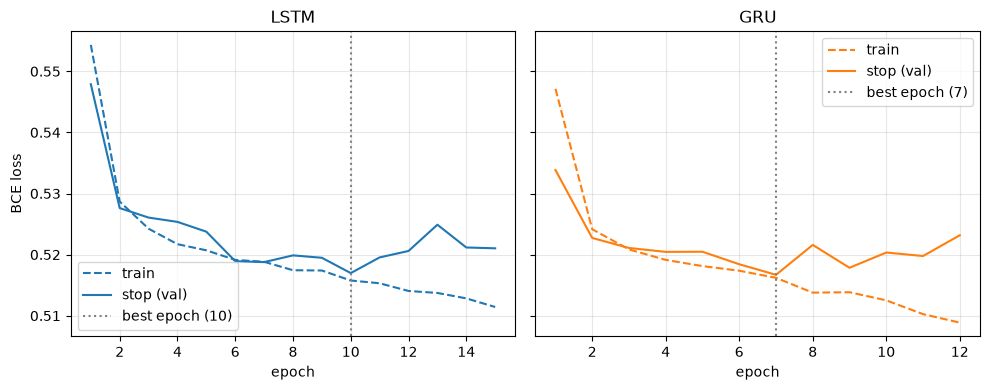

In [9]:
from src.models.evaluation.optuna_history import plot_training_history

COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
history_fig = plot_training_history(
    tuple(MODELS), save_path=COMPARISON_DIR / "training_history.png"
)
plt.show()

## 4. Test

For each model, the threshold was already selected on `tune` and is now frozen. The final refit uses all of February (`development`) for the `best_epoch` found during tuning. March is then predicted once.

A checkpoint with the architecture, parameters, threshold and epoch count is saved to `artifacts/sherlock_w2_v6_manual/<model>/checkpoints/<model>.pt`. The refit time is also recorded, so the comparison can report time per epoch.

In [10]:
from src.models.recurrent_models.test import test_model


def make_builder(model_cls):
    """Build ``model_cls`` from the tuned hyper-parameters."""
    def build(best_params, input_dim):
        return model_cls(
            input_dim=input_dim,
            hidden_dim=int(best_params["hidden_dim"]),
            layer_dim=int(best_params["layer_dim"]),
            output_dim=OUTPUT_DIM,
        )
    return build


results = {}
for name, model_cls in MODELS.items():
    print(f"\n===== {name.upper()} =====")
    results[name] = test_model(
        best[name]["best_params"],
        data,
        threshold=best[name]["threshold"],
        best_epoch=best[name]["best_epoch"],
        device=DEVICE,
        seed=SEED,
        verbose=True,
        build_model=make_builder(model_cls),
        model_name=name,
    )

pd.DataFrame(
    {
        name.upper(): {
            "test users": len(result["proba_test"]),
            "predicted churn rate": result["pred_test"].mean(),
            "threshold": result["threshold"],
            "epochs": result["epochs"],
            "seconds / epoch": result["seconds_per_epoch"],
            "checkpoint": str(result["checkpoint"]),
        }
        for name, result in results.items()
    }
)


===== LSTM =====
scaled tensor for phase 'development' cached in 6.5s
final | epoch 01 | train=0.54920
final | epoch 02 | train=0.52646
final | epoch 03 | train=0.52230
final | epoch 04 | train=0.52039
final | epoch 05 | train=0.51966
final | epoch 06 | train=0.51860
final | epoch 07 | train=0.51677
final | epoch 08 | train=0.51618
final | epoch 09 | train=0.51556
final | epoch 10 | train=0.51476

===== GRU =====
final | epoch 01 | train=0.54054
final | epoch 02 | train=0.52287
final | epoch 03 | train=0.52020
final | epoch 04 | train=0.51776
final | epoch 05 | train=0.51698
final | epoch 06 | train=0.51649
final | epoch 07 | train=0.51419


,LSTM,GRU
test users,113870,113870
predicted churn rate,0.464301,0.439053
threshold,0.3,0.33
epochs,10,7
seconds / epoch,2.13822,1.476661
checkpoint,artifacts/sherlock_w2_v6_manual/lstm/checkpoin...,artifacts/sherlock_w2_v6_manual/gru/checkpoint...


## 5. Per-model diagnostics

`evaluate_model` writes the complete evaluation of each model to `artifacts/sherlock_w2_v6_manual/<model>/evaluation/`:

- `test` metrics at the `tune` threshold,
- complementary metrics at `0.5`,
- classification report,
- confusion matrix,
- reliability/histogram,
- threshold manifest,
- training history of the best trial.

These are internal diagnostics, so they are shown **one model at a time**. The direct comparison (ROC/PR, gain/lift, tables) is in section 6.

`log_loss` measures probability quality. `ROC-AUC` and `average_precision` measure ranking. `F1`, `precision` and `recall` measure decisions at the chosen threshold.

In the confusion matrix:

- **FN**: churners the model missed.
- **FP**: loyal customers flagged as at risk.

Each threshold was selected in February and is not optimised again in March.

In [11]:
from src.models.evaluation import evaluate_model

reports = {
    name: evaluate_model(
        results[name],
        best[name],
        data,
        model_name=name,
        show_plots=False,
    )
    for name in MODELS
}
pd.concat([report["display"] for report in reports.values()], ignore_index=True)

,model_id,family,input,n_channels,n_parameters,best_epoch,tune_log_loss,log_loss,roc_auc,average_precision,brier,accuracy,balanced_accuracy,precision_churn,recall_churn,specificity,f1_churn,f1_macro,mcc,threshold
0,LSTM,lstm,sequence,14,53953,10,0.51132,0.57384,0.77658,0.71876,0.19545,0.71996,0.72060,0.64103,0.72417,0.71703,0.68006,0.71554,0.43526,0.30
1,GRU,gru,sequence,14,40513,7,0.51181,0.57988,0.76521,0.70051,0.19900,0.71379,0.70958,0.64210,0.68594,0.73322,0.66330,0.70720,0.41556,0.33



===== LSTM =====
confusion_png -> artifacts/sherlock_w2_v6_manual/lstm/evaluation/figures/confusion/confusion_LSTM_test.png


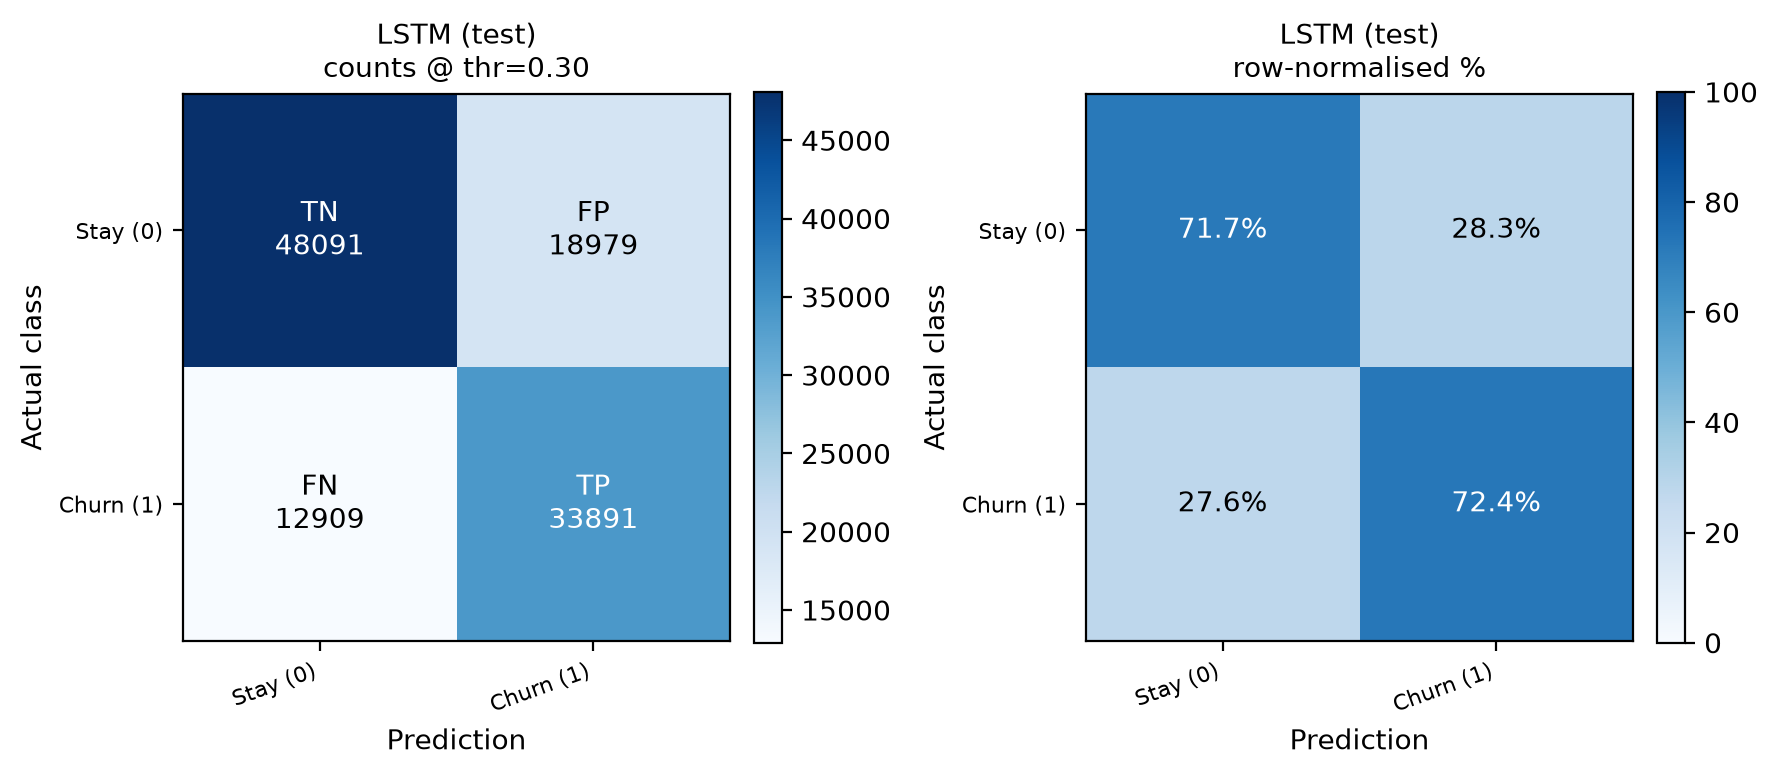

calibration -> artifacts/sherlock_w2_v6_manual/lstm/evaluation/figures/curves/calibration_hist.png


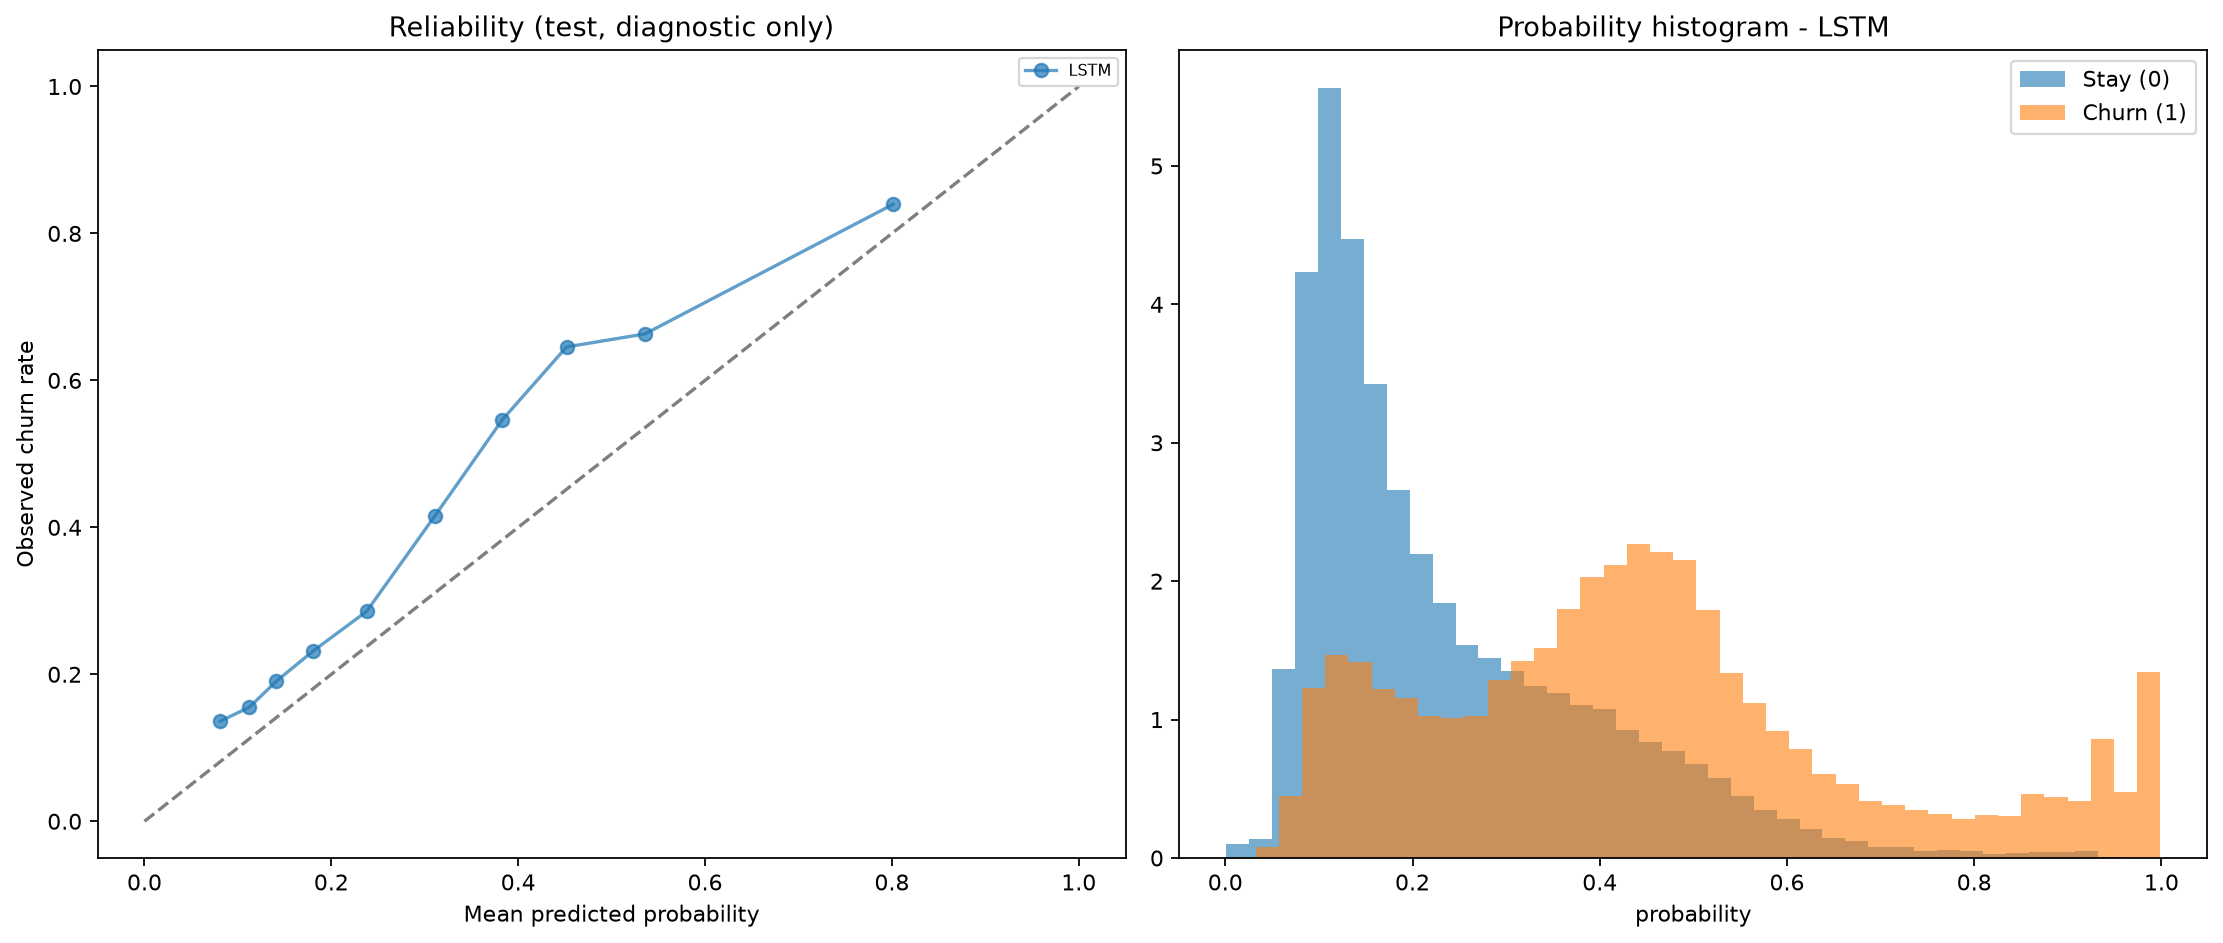

optuna_history -> artifacts/sherlock_w2_v6_manual/lstm/evaluation/figures/lstm_training_history.png


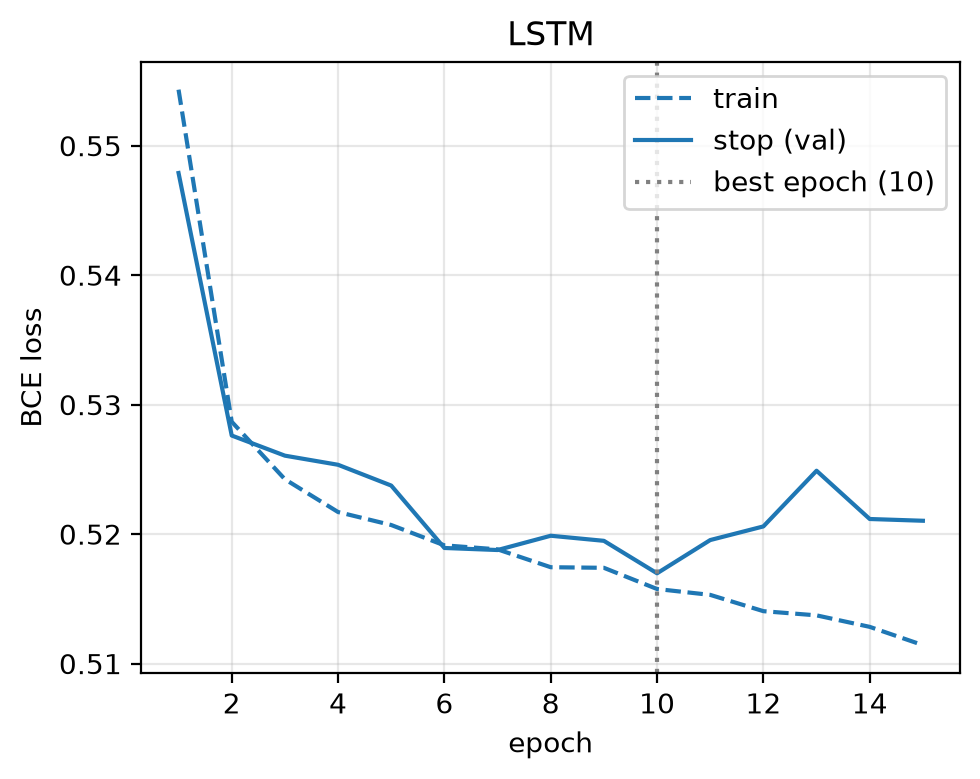


===== GRU =====
confusion_png -> artifacts/sherlock_w2_v6_manual/gru/evaluation/figures/confusion/confusion_GRU_test.png


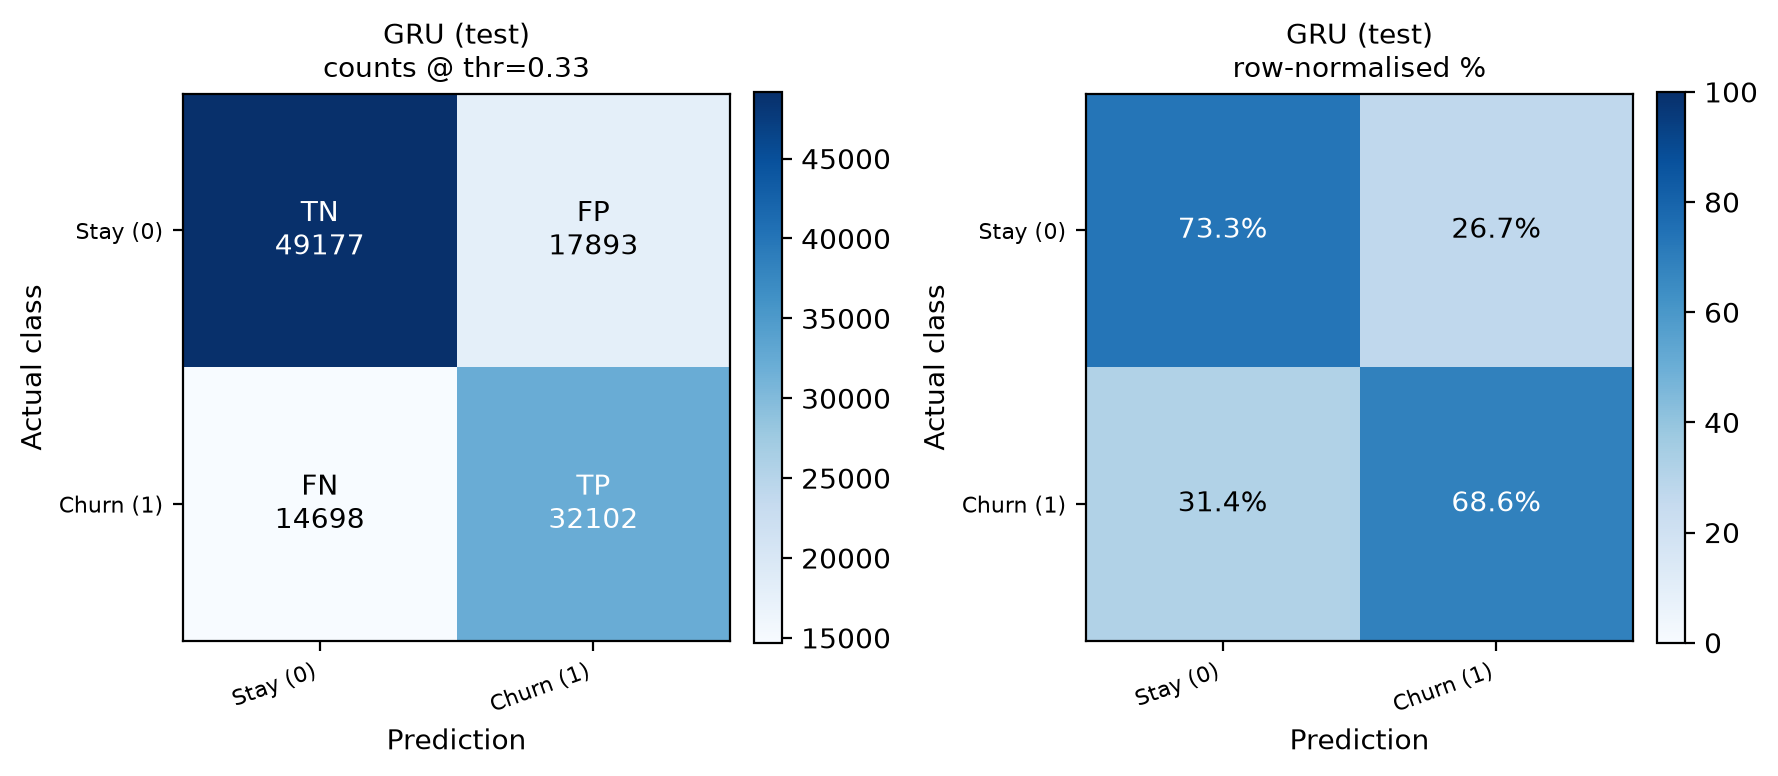

calibration -> artifacts/sherlock_w2_v6_manual/gru/evaluation/figures/curves/calibration_hist.png


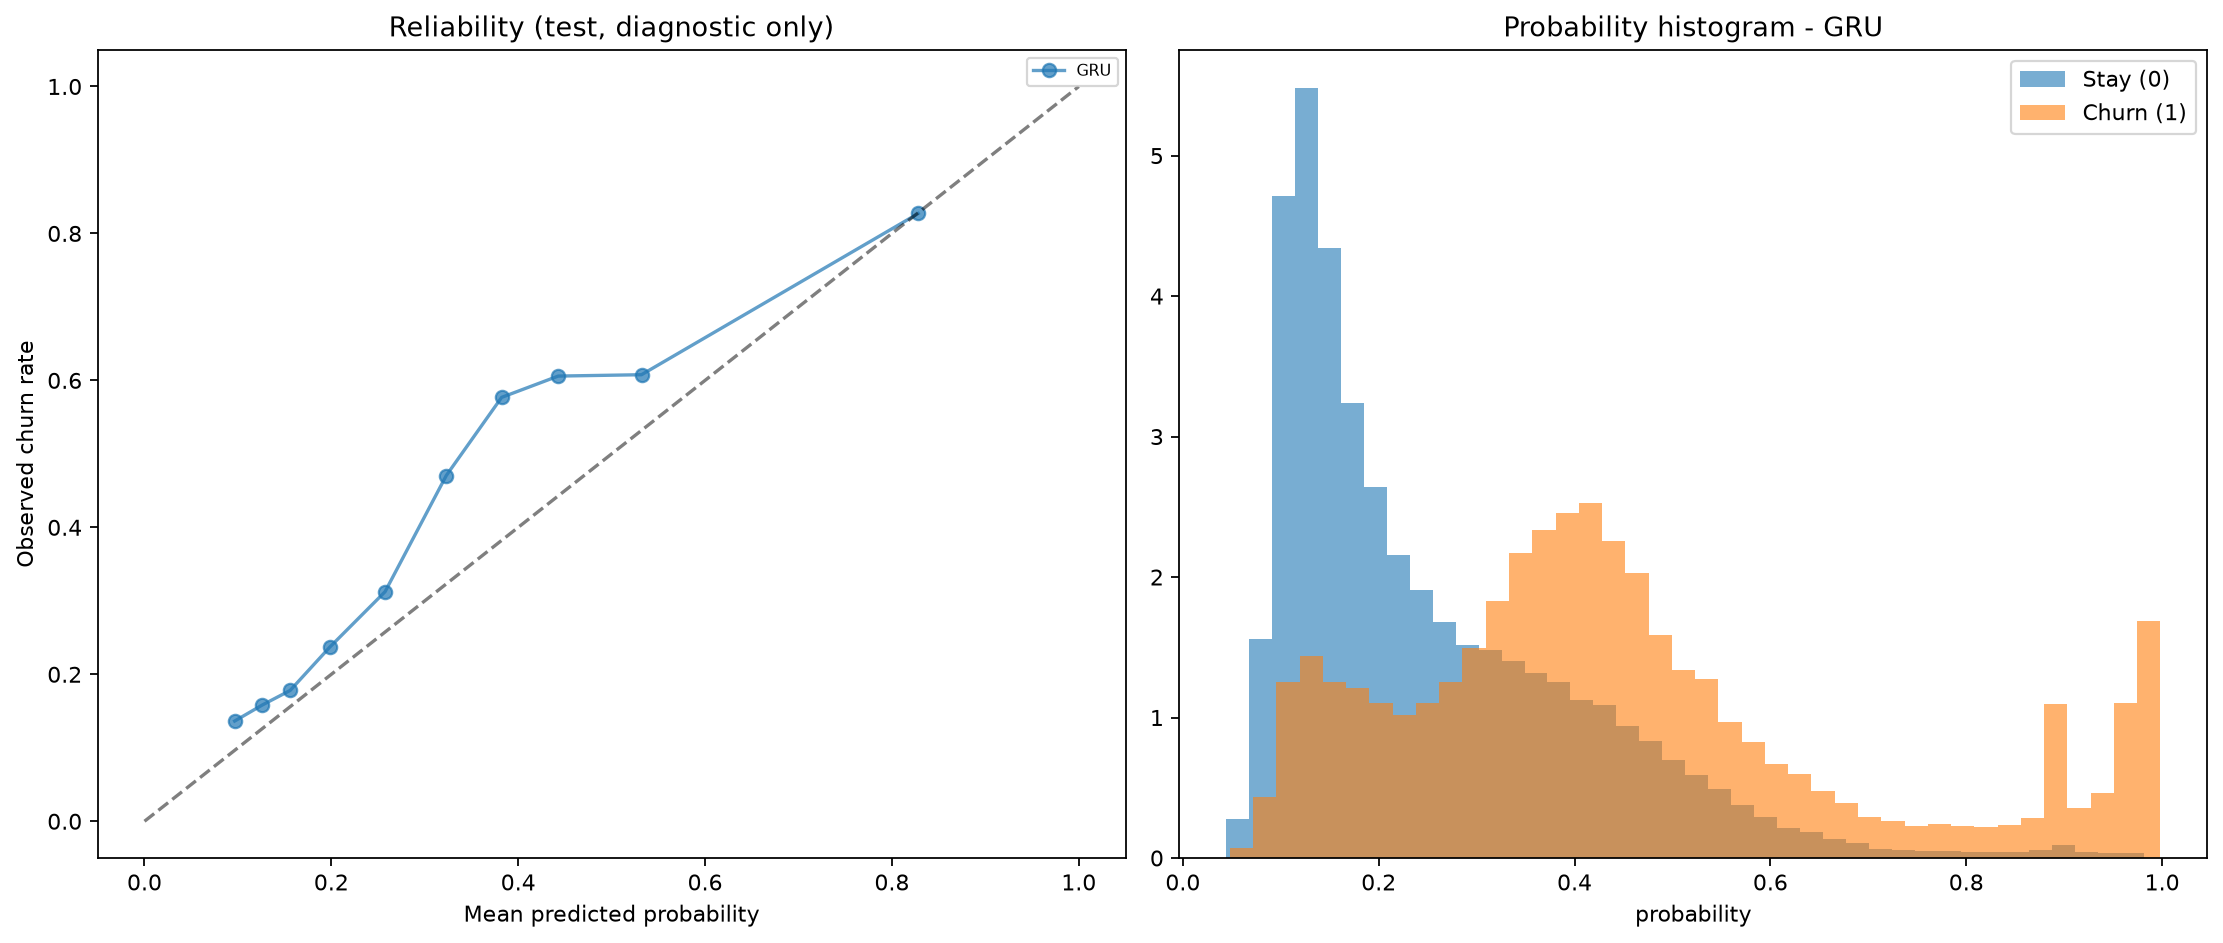

optuna_history -> artifacts/sherlock_w2_v6_manual/gru/evaluation/figures/gru_training_history.png


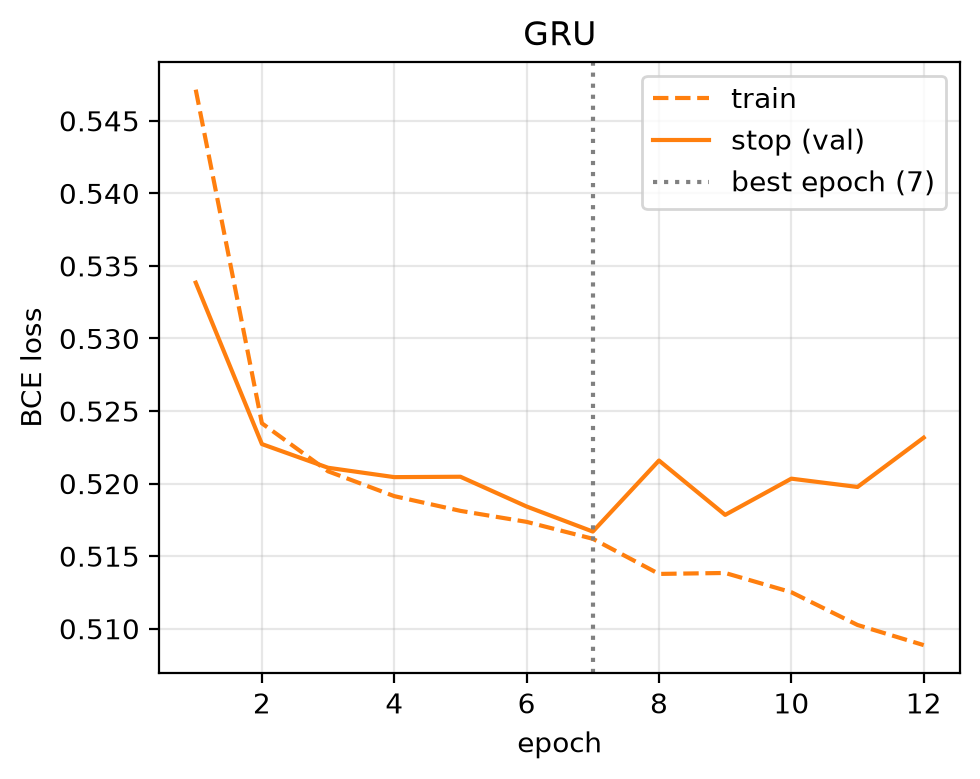

In [12]:
for name, report in reports.items():
    print(f"\n===== {name.upper()} =====")
    for key in ("confusion_png", "calibration", "optuna_history"):
        path = report["paths"].get(key)
        if path is not None and Path(path).is_file():
            print(key, "->", path)
            display(Image(filename=str(path)))

## 6. LSTM vs GRU comparison

`compare_models` puts both models on the same axes and in the same tables, with LSTM always in blue and GRU always in orange:

- **ROC and Precision-Recall**, one line per model. PR is the more informative one because churn is the minority class.
- **Cumulative gain and lift**: share of churners captured when contacting the top-risk users first, for retention campaigns.
- **Metrics table**: AUC-ROC, AUC-PR, F1, log-loss, parameters and time per epoch, with the best value of each column in bold.
- **Paired bootstrap** (1000 resamples of the test users): 95% intervals per model and for the difference LSTM − GRU. Both models are scored on the same resampled users, so the interval of the difference accounts for their correlation. A difference is significant when its interval excludes 0.
- **DeLong test** for the difference in AUC-ROC.
- **Best hyper-parameters** of each model (annex table).

Every metric uses each model's own `tune` threshold; nothing is tuned on `test`.

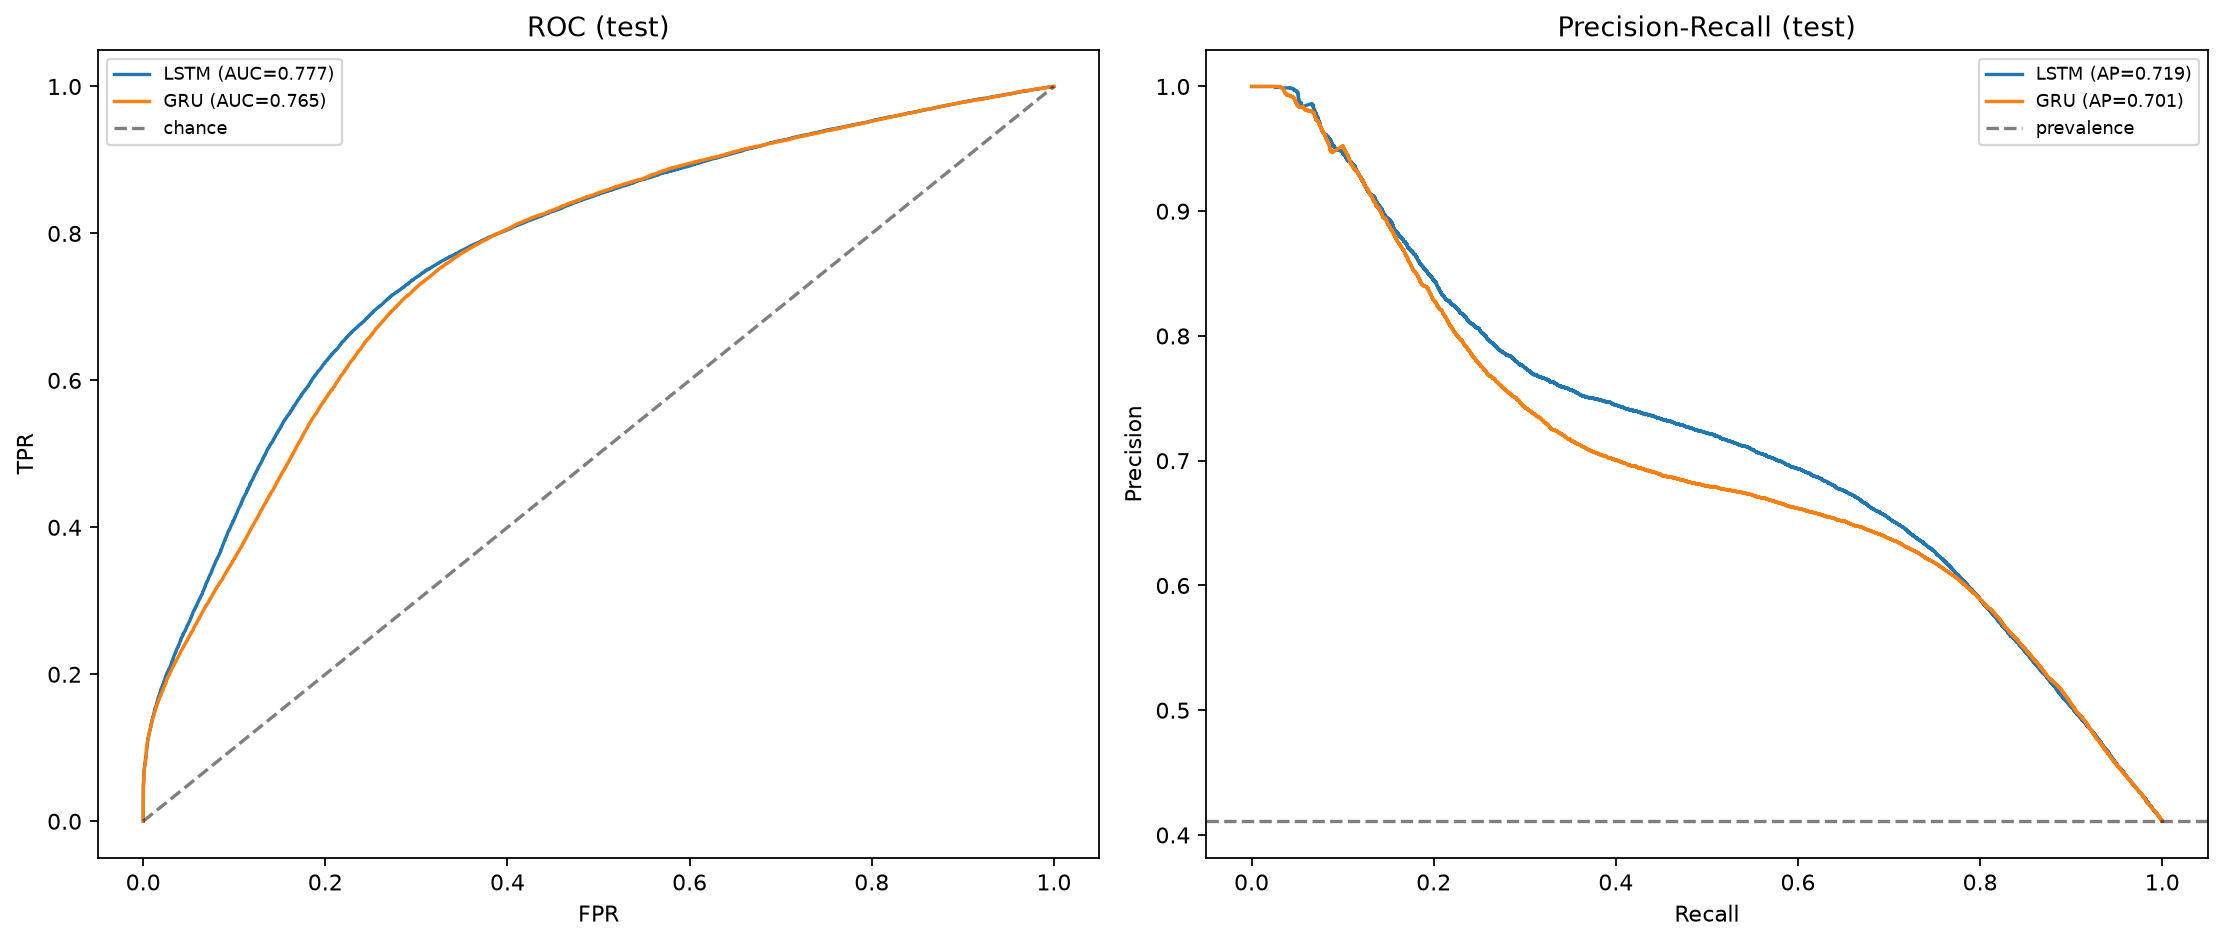

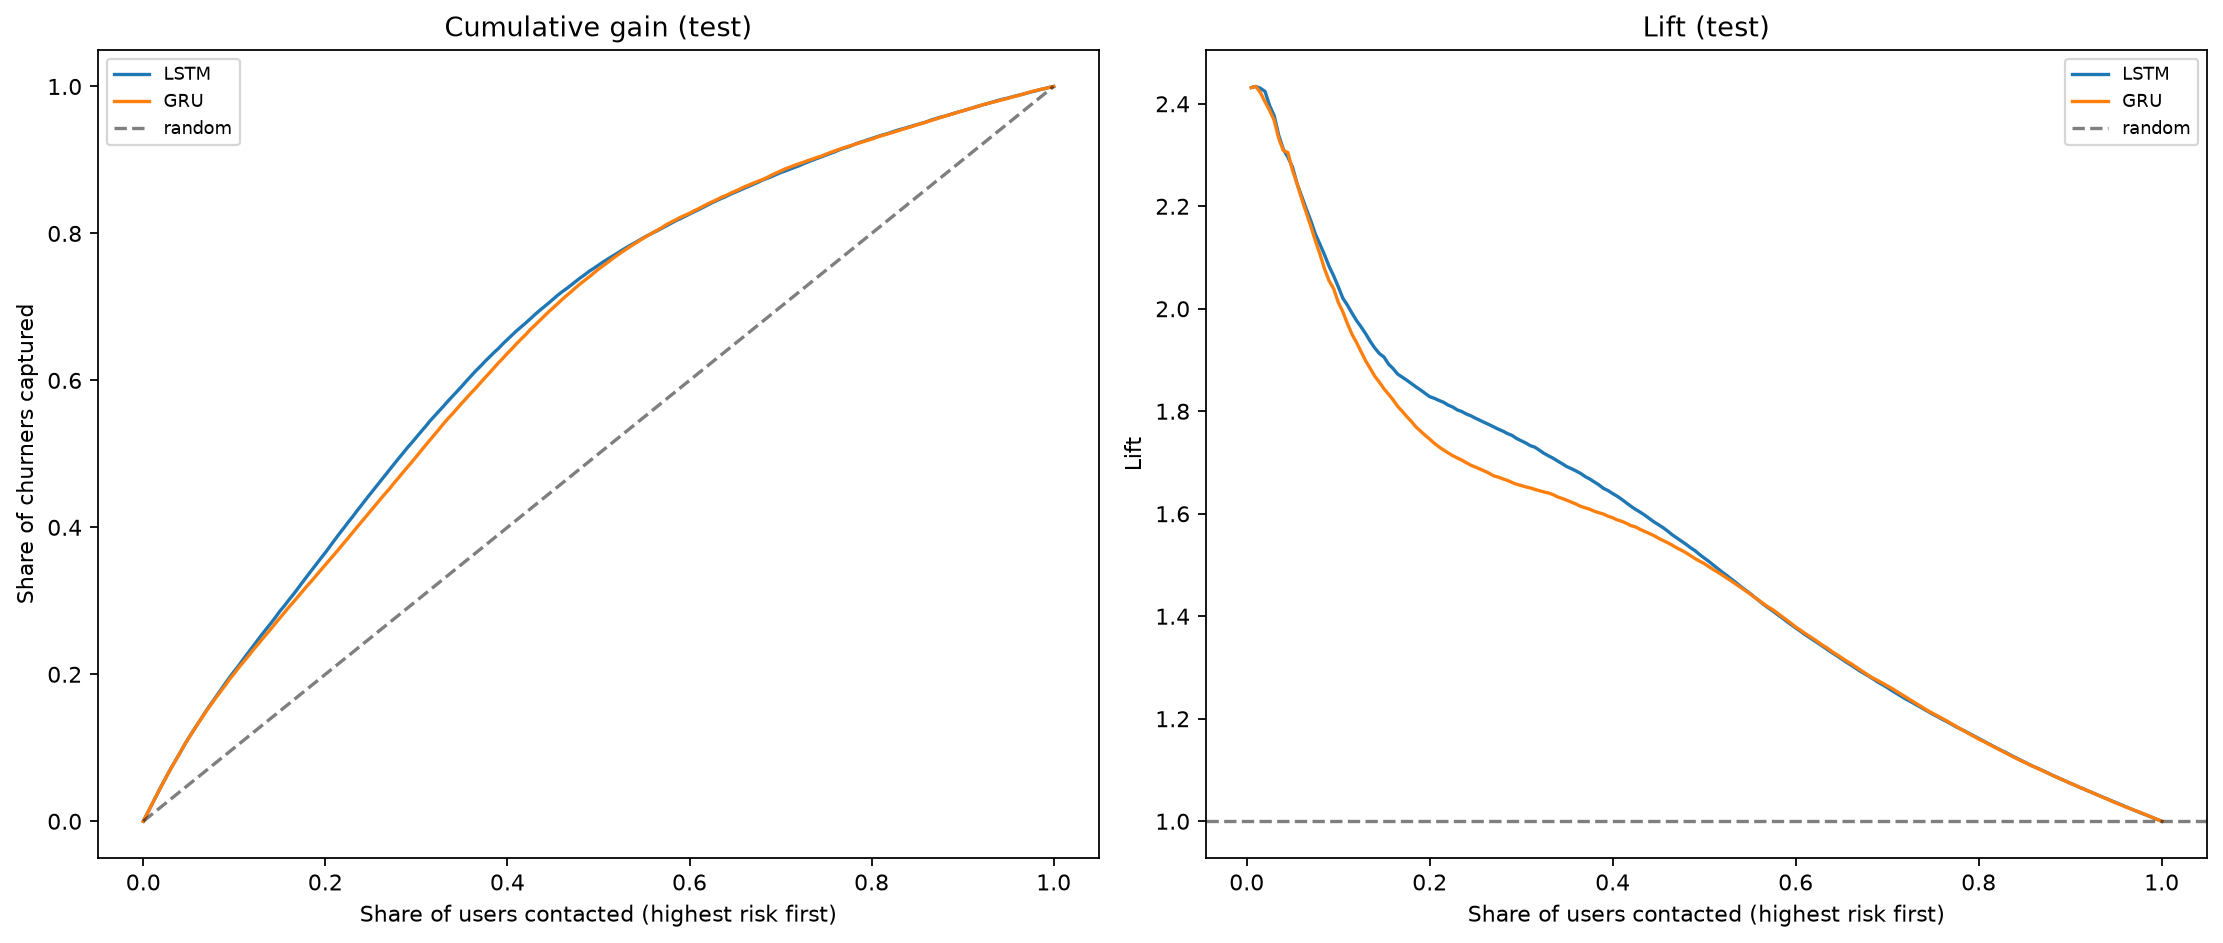

,AUC-ROC,AUC-PR,F1,Log-loss,Parámetros,Tiempo/época (s),Umbral
Modelo,,,,,,,
LSTM,0.7766,0.7188,0.6801,0.5738,"53,953",2.14,0.30
GRU,0.7652,0.7005,0.6633,0.5799,"40,513",1.48,0.33


In [13]:
from src.models.evaluation import compare_models

comparison = compare_models(runs=results, tunes=best, show_plots=False)

for key in ("roc_pr", "gain_lift"):
    display(Image(filename=str(comparison["paths"][key])))

comparison["display"]

In [14]:
print("Paired bootstrap, 95% CI (difference = LSTM - GRU)")
display(comparison["bootstrap"])

delong = comparison["delong"]
print(
    f"DeLong AUC-ROC: {delong['model_a']}={delong['auc_a']:.4f}"
    f" | {delong['model_b']}={delong['auc_b']:.4f}"
    f" | diff={delong['diff']:+.4f} | z={delong['z']:.2f} | p={delong['p_value']:.3g}"
)

print("\nGain and lift at fixed contact rates")
display(comparison["lift"].round(3))

print("Best hyper-parameters (annex)")
display(comparison["hyperparams"])

Paired bootstrap, 95% CI (difference = LSTM - GRU)


,LSTM,LSTM IC95,GRU,GRU IC95,Δ LSTM-GRU,Δ IC95,Significativo
Métrica,,,,,,,
AUC-ROC,0.776583,"[0.7740, 0.7791]",0.765209,"[0.7625, 0.7679]",0.011374,"[0.0103, 0.0124]",True
AUC-PR,0.718760,"[0.7150, 0.7226]",0.700514,"[0.6965, 0.7046]",0.018245,"[0.0168, 0.0197]",True
F1,0.680064,"[0.6769, 0.6832]",0.663299,"[0.6600, 0.6665]",0.016765,"[0.0148, 0.0189]",True
Log-loss,0.573839,"[0.5706, 0.5771]",0.579882,"[0.5770, 0.5830]",-0.006043,"[-0.0070, -0.0051]",True


DeLong AUC-ROC: LSTM=0.7766 | GRU=0.7652 | diff=+0.0114 | z=21.36 | p=2.91e-101

Gain and lift at fixed contact rates


Churners capturados          Lift       
Modelo                        LSTM    GRU   LSTM    GRU
Top contactado                                         
5%                           0.114  0.114  2.276  2.271
10%                          0.204  0.201  2.043  2.013
20%                          0.366  0.349  1.828  1.746
30%                          0.523  0.497  1.743  1.655

Best hyper-parameters (annex)


,layer_dim,hidden_dim,lr,weight_decay,batch_size,best_epoch,trial,tune log-loss
Modelo,,,,,,,,
LSTM,2,64,0.006419,0.000002,512,10,5,0.511322
GRU,2,64,0.006307,0.000002,512,7,5,0.511814


## 7. Artifacts and limitations

Generated artifacts:

```text
artifacts/sherlock_w2_v6_manual/
├── feature_preparation/          # split, labels and scalers (shared)
├── lstm/
│   ├── optuna/                   # study, trials, best params, best-trial history
│   ├── checkpoints/lstm.pt       # final model
│   └── evaluation/
│       ├── metrics/
│       ├── figures/
│       └── selection_manifest.json
├── gru/                          # same layout as lstm/
│   ├── optuna/
│   ├── checkpoints/gru.pt
│   └── evaluation/
└── comparison/
    ├── roc_pr_comparison.png
    ├── gain_lift_comparison.png
    ├── training_history.png
    ├── comparison_metrics.csv
    ├── bootstrap_ci.csv
    ├── delong_auc.json
    ├── gain_lift_cutoffs.csv
    └── best_hyperparams.csv
```

Limitations:

- There is only one test month: March.
- Validation is used for early stopping, tuning and the threshold, so validation metrics are optimistic.
- No probability calibration was applied.
- Each final model is trained with a single seed. The bootstrap intervals cover sampling noise in the test set, not the variation from weight initialisation; a small gap between LSTM and GRU could change with another seed.
- Time per epoch is measured on the final refit and is only comparable when both models run on the same device.
- Churn prevalence changes between February and March; that shift is part of the honest evaluation.